# 01 — Motion evidence: who moved, and who merely changed the lighting?

Object tracking begins with a deceptively modest question: **what changed between frames?** We will answer it with a fixed camera, one indecisive robot, and eventually a real OpenCV sample video.

The important warning arrives early: **motion detection is not yet object tracking**. A mask can tell us where pixels changed. It does not remember identities, understand objects, or file a missing-robot report.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

from _helpers.motion_background import (
    ensure_opencv_sample_video,
    make_robot_sequence,
    plot_background_learning,
    plot_cloud_reveal,
    plot_frame_difference,
    plot_mog2_sequence,
    plot_motion_failures,
    plot_real_video_motion,
    plot_sequence_strip,
    plot_threshold_sweep,
    read_video_frames,
)

# Enough detail for the experiments without storing several wallpaper-sized PNGs.
plt.rcParams['figure.dpi'] = 75

## 1. A tiny security-camera drama

Our camera stays still while a robot moves, pauses, and continues. A stationary tree supervises the experiment without signing the consent form. Meanwhile, a cloud initially covers the sun and slowly moves away, making every early frame a little brighter. Because the scene is synthetic, we know what truly happened before asking an algorithm to invent an opinion.

This is already more realistic than a sudden brightness switch: outdoor illumination can drift while the object of interest does something entirely unrelated. We will try to determine whether the robot moved, the weather moved, or our simulated universe has begun making independent decisions.

> Curious how the robot was assembled from innocent rectangles and circles? [`make_robot_sequence()` implementation](./_helpers/motion_background.py).

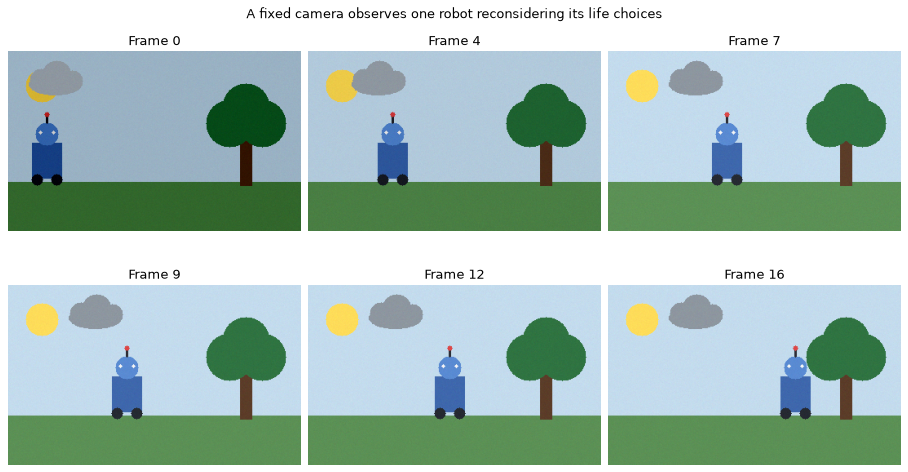

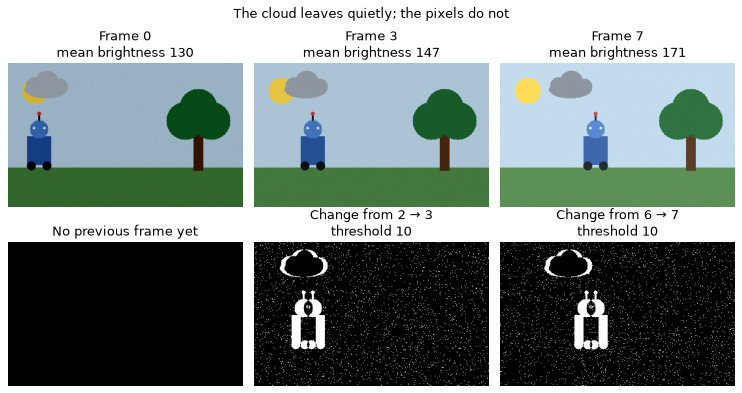

In [2]:
frames, true_robot_masks, true_centers = make_robot_sequence()
plot_sequence_strip(frames)
plot_cloud_reveal(frames, frame_indices=(0, 3, 7), threshold=10)

## 2. Consecutive-frame differencing

The simplest motion detector compares two neighboring frames:

1. subtract the previous frame from the current one using absolute differences;
2. convert the difference to one gray value per pixel;
3. keep differences larger than a threshold;
4. use morphology to remove tiny noise and reconnect useful regions;
5. group touching foreground pixels into connected components.

No long formula is hiding here. We ask each pixel whether it changed enough to become suspicious.

Notice the two-part ghost around the robot: one region marks **where it was**, another marks **where it arrived**. Frame differencing detects change, not a perfectly filled object.

> If subtracting robots by hand becomes your calling: [`motion_mask()` and `foreground_boxes()` implementation](../../src/wave_part_dual/tracking/background.py).

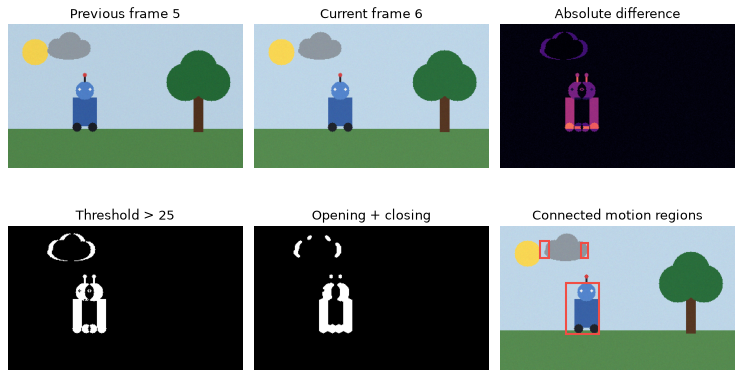

In [3]:
difference_result = plot_frame_difference(
    frames, previous_index=5, current_index=6, threshold=25
)

### A threshold is a suspicion dial

A lower threshold treats small changes as motion: sensitive, but easily impressed by noise. A higher threshold demands stronger evidence: calmer, but capable of ignoring subtle motion.

Our original scene is unusually well behaved: its noise stays mostly below `10`, while the robot's strong edges exceed `50`. All three thresholds therefore reach almost the same conclusion. For this experiment we create a **noisier copy of the same movement**, giving the thresholds something worth disagreeing about. The percentages report how much of the image each threshold accuses before and after morphology.

The morphology cleanup is the same opening-and-closing machinery from [classical CV notebook 01](../classical_cv/01_color_detection_pipeline.ipynb). It has returned with a job.

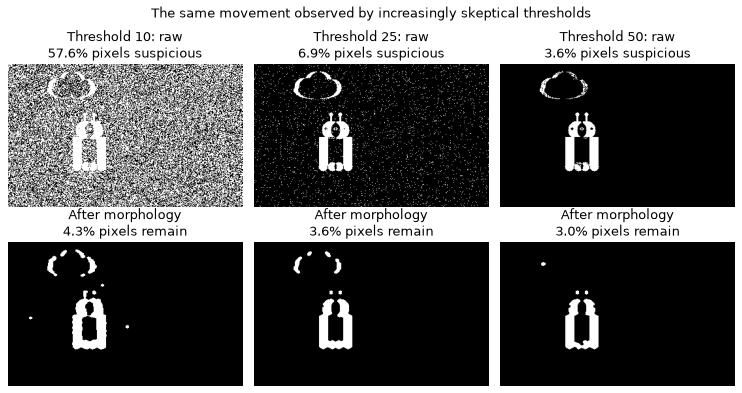

In [4]:
noisy_frames, _, _ = make_robot_sequence(
    noise_sigma=10, seed=7
)
threshold_results = plot_threshold_sweep(
    noisy_frames, thresholds=(10, 25, 50), previous_index=5, current_index=6
)

> **Threshold observation:** `10` promotes a spectacular amount of noise before morphology rescues the robot. `25` removes most accidental accusations while preserving its shape. `50` keeps only the strongest changes and makes the detected region slightly thinner. The best value depends on how noisy and subtle the actual motion is.

## 3. Three ways changed pixels can mislead us

Frame differencing quietly assumes that interesting motion causes the image change and everything else behaves. Reality did not accept these terms.

- While the robot moves, differences are useful.
- When it pauses, consecutive frames become nearly identical and the robot disappears from the motion mask. It still exists; it merely stopped generating new evidence.
- While the cloud moves away, both its position and the scene illumination change. The detector sees changed pixels but cannot explain whether they came from the robot, the weather, or both. A low threshold makes this gradual lighting drift especially visible.

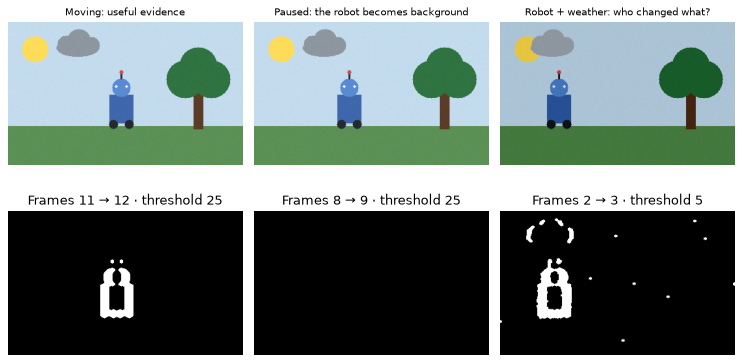

In [5]:
plot_motion_failures(frames, threshold=25, illumination_threshold=5)

## 4. Remembering a background

Instead of comparing only with the previous frame, we can maintain an estimate of the usual background. Each new frame updates it a little:

`new background = mostly old background + a little current frame`

The learning rate `α` controls **how quickly the model changes its mind**. A small value remembers for longer but adapts slowly. A large value adapts quickly but may absorb a stopped object into the background—the robot is gradually reclassified as furniture.

> The reusable machinery lives in [`running_background_masks()`](../../src/wave_part_dual/tracking/background.py), should inspecting the robot-to-furniture bureaucracy suddenly become unavoidable.

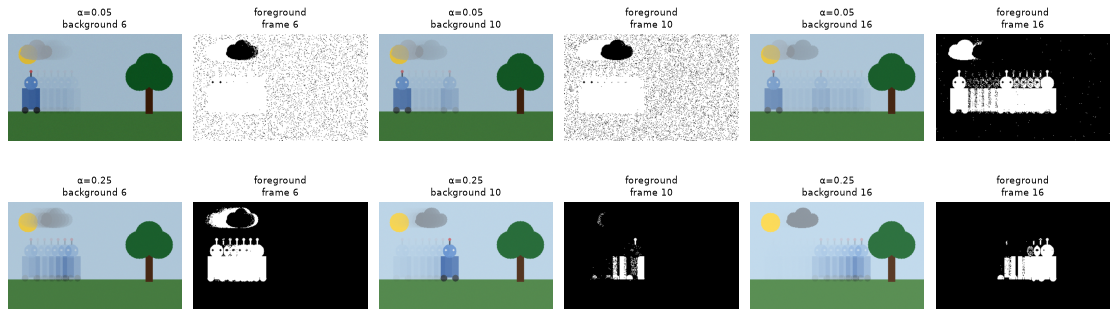

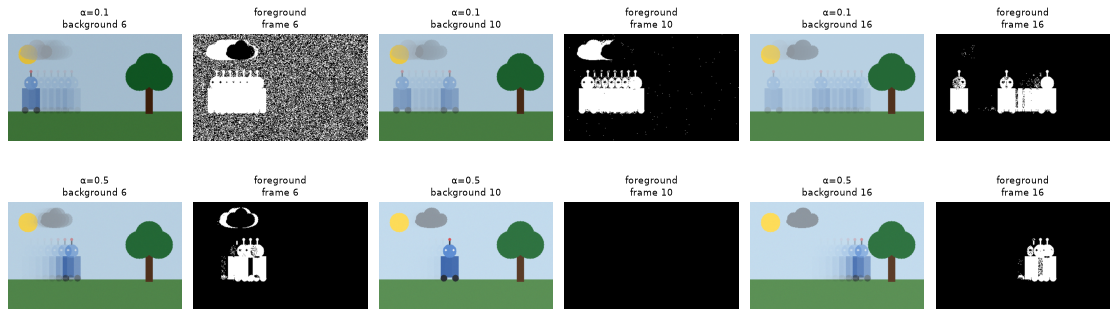

In [6]:
plot_background_learning(
    frames, alphas=(0.05, 0.25), frame_indices=(6, 10, 16)
)
plot_background_learning(
    frames, alphas=(0.1, 0.5), frame_indices=(6, 10, 16)
)

This running average is deliberately simple. Real background subtractors can model repeated variation—leaves, water, monitor flicker—more carefully than one average image can. But the basic bargain remains: **adapt too slowly and old history lingers; adapt too quickly and foreground becomes background.**

> **A slightly ridiculous observation:** with a small `α`, frames 6 and 10 can become almost entirely white because the model still remembers the darker frame 0. The slowly moving cloud may remain black because its gray appearance changes less and overlaps its recent positions. The model therefore considers the brightening stationary world suspicious while accepting the cloud as relatively normal. White means **different from my learned background**, not necessarily **this object moved**.

> **Learning-rate observation:** smaller values preserve old robot positions and outdated illumination for longer. Larger values catch up quickly, but also absorb the paused robot into the background sooner. Memory and adaptability remain professionally unwilling to coexist for free.

## 5. OpenCV MOG2: several normal backgrounds are allowed

`cv2.createBackgroundSubtractorMOG2` keeps a statistical background model for each pixel. **MOG** means *Mixture of Gaussians*: a pixel can have several ordinary appearances instead of one sacred value. That is helpful when the background itself wiggles.

The parameters worth touching today are:

- `history`: roughly how much recent history influences the model;
- `varThreshold`: how different a pixel must look before becoming foreground;
- `detectShadows`: whether likely shadows receive the separate gray value `127` instead of foreground value `255`.

The first mask is mostly foreground because MOG2 has just arrived and knows nothing. Background models, like people, should not be judged entirely by their first day at work.

Official reassurance: [OpenCV background-subtraction tutorial](https://docs.opencv.org/4.x/d1/dc5/tutorial_background_subtraction.html) and [`BackgroundSubtractorMOG2` documentation](https://docs.opencv.org/4.x/d7/d7b/classcv_1_1BackgroundSubtractorMOG2.html).

> Are you a robot? Why else would you voluntarily inspect the code?: [`plot_mog2_sequence()` helpers implementation](./_helpers/motion_background.py).

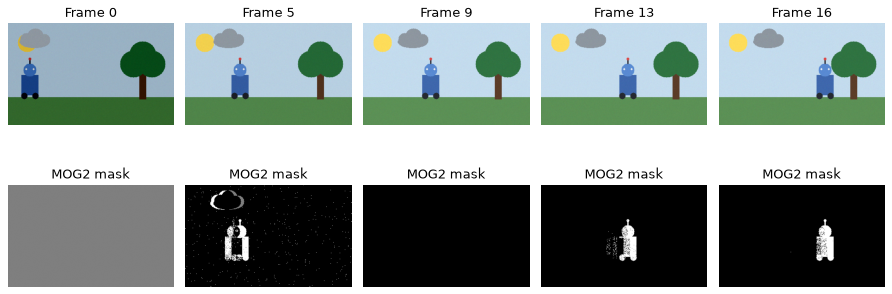

In [7]:
mog2_masks = plot_mog2_sequence(
    frames, history=40, var_threshold=24, detect_shadows=True
)

### Small parameter experiment

Try a more suspicious `var_threshold=12` and a more relaxed `var_threshold=48`. Then turn shadow detection off. The synthetic scene has weak shadows, so that switch becomes more interesting on the real video below.

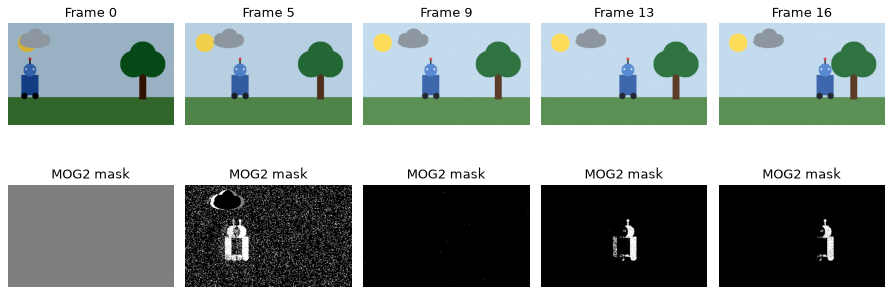

In [8]:
var_threshold = 12
history = 20
detect_shadows = True
_ = plot_mog2_sequence(
    frames, history=history, var_threshold=var_threshold, detect_shadows=detect_shadows
)

> **MOG2 observation:** lowering `varThreshold` makes the model more suspicious and produces more foreground; raising it ignores smaller deviations. Disabling shadow detection mainly removes the special gray `127` category—suspected shadows must then become ordinary foreground or background.

## 6. A real video, because robots made of rectangles are suspiciously cooperative

OpenCV publishes `vtest.avi`, a fixed-camera traffic sample used in its own background-subtraction tutorial. The helper downloads about 8 MB once into the ignored `data/` directory, then reuses the local copy. If the internet is unavailable, place your own video at that path.

We process frames **in order** because the background model has memory. Jumping directly to frame 190 would deprive it of the previous 189 frames of emotional development.

> If real-video plumbing suddenly becomes your calling: [`read_video_frames()` and plotting implementation](./_helpers/motion_background.py). The [sample itself lives in OpenCV's repository](https://github.com/opencv/opencv/blob/master/samples/data/vtest.avi).

In [9]:
video_path = ensure_opencv_sample_video(
    Path('../../data/object_tracking/vtest.avi')
)
real_frames, fps = read_video_frames(video_path, maximum_frames=220)
print(f'Read {len(real_frames)} frames at {fps:.1f} FPS')

Read 220 frames at 10.0 FPS


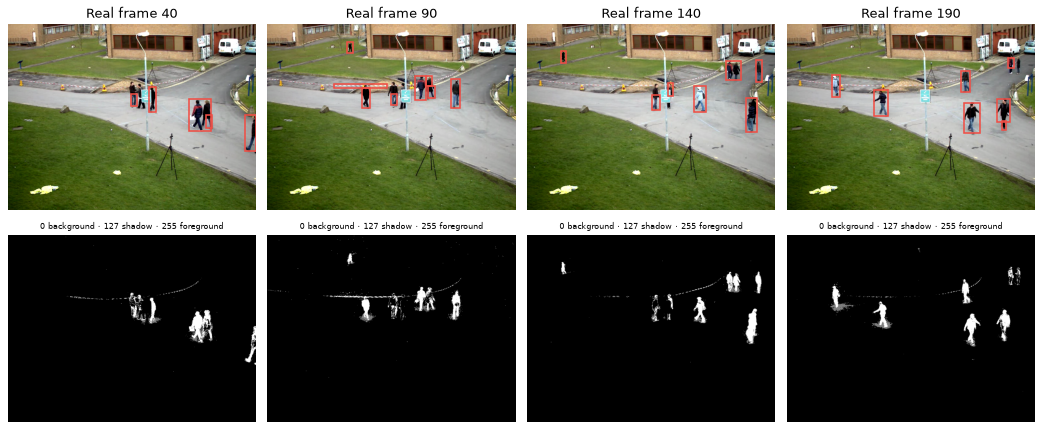

In [10]:
real_masks = plot_real_video_motion(
    real_frames,
    frame_indices=(40, 90, 140, 190),
    history=120,
    var_threshold=28,
    minimum_area=180,
)

The red rectangles surround connected foreground regions, **not reliably tracked objects**. One human being may split into several regions; several nearby objects may merge; shadows may remain; a box has no identity from one frame to the next. We have built a useful front end for tracking, not tracking itself.

A practical pipeline can now begin as:

**video → background model → foreground mask → cleanup → connected regions → candidate detections**

The next notebooks can ask how those candidates move and whether the box in frame 91 is the same creature seen in frame 90.

> **Region-size observation:** lowering `minimum_area` gives small motion regions rectangles too—including more noise and fragmented body parts. Raising it reduces clutter but can dismiss distant or small people entirely. It filters candidate boxes after the mask is created; it does not improve the foreground mask itself.

## Reflection

A few questions for future me, with no obligation to produce a dissertation:

1. Why can one moving object create two regions in consecutive-frame differencing?
    - Its old location changes from object to background, while its new location changes from background to object. Both regions therefore appear in the difference.
2. Why does a stopped object disappear from a motion mask even though it remains visible?
    - It remains unchanged between frames, while this experiment relies only on frame differences.
3. What does a background model's learning rate change?
    - It controls the inertia of background learning: how quickly new frames replace old knowledge.
4. Why would moving the camera break most of this notebook?
    - The entire background shifts between frames, so almost every pixel may appear to move.
5. What information is still missing before we can call this object tracking?
    - The objects themselves and their identities. For now, we only have candidate regions without knowing which region belongs to the same object over time.

## Takeaway

Background subtraction converts temporal change into candidate foreground regions. It works especially well with a fixed camera and a reasonably stable scene, but lighting changes, shadows, camera motion, pauses, and changing backgrounds all test its confidence.

Most importantly: **foreground is evidence, not identity**. Today we found suspicious pixels. The tracking paperwork begins next.